# LLM Hallucination Detection using HaluEval
## Student 2: SVM Model Development and Hyperparameter Tuning

### Objective
Develop a Support Vector Machine (SVM) classifier to distinguish between:
- **0 — Faithful:** An answer supported by the provided knowledge.
- **1 — Hallucinated:** An answer unsupported by or inconsistent with the provided knowledge.

### Data and Input
Use the existing training dataset (`halu_train.csv`) without changing the original Train/Test split.

- **Input:** The `text` column, which combines knowledge, question, and candidate answer.
- **Target:** The `label` column.
- **Groups:** The `question` column, used to keep records sharing the same question in the same cross-validation fold.

### Method
Build a Pipeline containing TF-IDF text representation and a LinearSVC classifier.

### Validation and Hyperparameter Tuning
- Use 5-fold GroupKFold cross-validation on the training dataset.
- Report Accuracy, Precision, Recall, and F1-score.
- Treat **1 — Hallucinated** as the positive class.
- Use GridSearchCV and select the best hyperparameters using mean validation F1-score.

### Scope
Save the best trained SVM Pipeline for Student 3.
The test dataset will not be loaded or evaluated in this notebook.


In [1]:
# Check the Python and library versions before starting.
import sys
import pandas as pd
import numpy as np
import sklearn
import joblib
import matplotlib

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3
scikit-learn: 1.6.1
joblib: 1.6.0
Matplotlib: 3.10.0


In [2]:
# Upload the existing training dataset only.
from google.colab import files

uploaded = files.upload()

Saving halu_train.csv to halu_train.csv


In [3]:
# Load the original training split.
train_data = pd.read_csv("halu_train.csv")

print("Training shape:", train_data.shape)
print("Columns:", train_data.columns.tolist())

train_data.head(3)

Training shape: (16000, 5)
Columns: ['knowledge', 'question', 'answer', 'label', 'text']


,knowledge,question,answer,label,text
0,Vincenzo Salvatore Carmelo Francesco Bellini (...,"Who has knowledge of more arts, Vincenzo Belli...",Igor Fyodorovich Stravinsky,0,Knowledge: Vincenzo Salvatore Carmelo Francesc...
1,Vincenzo Salvatore Carmelo Francesco Bellini (...,"Who has knowledge of more arts, Vincenzo Belli...",Vincenzo Bellini had more knowledge.,1,Knowledge: Vincenzo Salvatore Carmelo Francesc...
2,"The Naga Chili, closely related to the Bhut jo...","The Naga Chili, closely related to the Bhut jo...",Bangladesh,0,"Knowledge: The Naga Chili, closely related to ..."


In [4]:
# Check missing values, duplicate rows, and class balance.
print("Missing values per column:")
print(train_data.isna().sum())

print("\nDuplicate rows:", train_data.duplicated().sum())

print("\nLabel counts:")
print(train_data["label"].value_counts().sort_index())

print("\nLabel percentages:")
print(
    train_data["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

Missing values per column:
knowledge    0
question     0
answer       0
label        0
text         0
dtype: int64

Duplicate rows: 0

Label counts:
label
0    8000
1    8000
Name: count, dtype: int64

Label percentages:
label
0    50.0
1    50.0
Name: proportion, dtype: float64


In [5]:
# Separate model inputs, target labels, and question groups.
X_train = train_data["text"]
y_train = train_data["label"]
groups = train_data["question"]

print("Training samples:", len(X_train))
print("Unique questions:", groups.nunique())

print("\nNumber of records per question:")
print(groups.value_counts().value_counts().sort_index())

# Verify that each question has one example from each class.
labels_per_question = train_data.groupby("question")["label"].agg(set)

assert set(y_train.unique()) == {0, 1}, "Unexpected labels."
assert groups.value_counts().eq(2).all(), "A question does not have two records."
assert labels_per_question.apply(lambda labels: labels == {0, 1}).all(), (
    "A question does not contain both labels."
)

print("\nGroup structure checks passed.")

Training samples: 16000
Unique questions: 8000

Number of records per question:
count
2    8000
Name: count, dtype: int64

Group structure checks passed.


## Preprocessing Decisions and Leakage Prevention

- The original training split contains 16,000 records from 8,000 questions.
- Each question has two answers: one Faithful (0) and one Hallucinated (1).
- No missing values or exact duplicate rows were found.
- The existing `text` column combines knowledge, question, and candidate answer. The `label` column is kept separate from the model input.
- The original Train/Test split is preserved. No new Train/Test split is created, and the test file is not loaded.

### Text Representation
TF-IDF converts text into numerical features. It gives greater weight to terms that are frequent within a document but less common across documents.

TF-IDF uses L2 normalization by default. No additional StandardScaler is applied.

### Preventing Data Leakage
TF-IDF will be fitted inside the Pipeline separately for each training fold. Validation documents will not be used to learn the vocabulary or IDF weights.

GroupKFold will keep all records sharing the same question together, preventing the same question from appearing in both training and validation within a fold.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

# Define the baseline text classification pipeline.
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2)
    )),
    ("svm", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

svm_pipeline

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=20000, ngram_range=(1, 2))),
                ('svm', LinearSVC(max_iter=5000, random_state=42))])

In [7]:
from sklearn.model_selection import GroupKFold

# Create reusable folds for baseline evaluation and tuning.
cv = GroupKFold(n_splits=5)
cv_splits = list(cv.split(X_train, y_train, groups=groups))

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    train_questions = set(groups.iloc[train_idx])
    val_questions = set(groups.iloc[val_idx])

    overlap = train_questions.intersection(val_questions)
    assert len(overlap) == 0, f"Question overlap in fold {fold}."

    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}, "
        f"Shared questions = {len(overlap)}"
    )

Fold 1: Train = 12800, Validation = 3200, Shared questions = 0
Fold 2: Train = 12800, Validation = 3200, Shared questions = 0
Fold 3: Train = 12800, Validation = 3200, Shared questions = 0
Fold 4: Train = 12800, Validation = 3200, Shared questions = 0
Fold 5: Train = 12800, Validation = 3200, Shared questions = 0


In [8]:
from sklearn.model_selection import cross_validate

# Evaluate the baseline using the same five question-grouped folds.
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

baseline_results = cross_validate(
    estimator=svm_pipeline,
    X=X_train,
    y=y_train,
    cv=cv_splits,
    scoring=scoring,
    n_jobs=2,
    error_score="raise"
)

# Display validation scores for each fold.
baseline_scores = pd.DataFrame({
    metric: baseline_results[f"test_{metric}"]
    for metric in scoring
})
baseline_scores.index = range(1, 6)
baseline_scores.index.name = "Fold"

print("Baseline cross-validation scores:")
print(baseline_scores.round(4))

print("\nMean and standard deviation across folds:")
print(baseline_scores.agg(["mean", "std"]).round(4))

Baseline cross-validation scores:
      accuracy  precision  recall      f1
Fold                                     
1       0.7378     0.7594  0.6962  0.7264
2       0.7294     0.7500  0.6881  0.7177
3       0.7281     0.7538  0.6775  0.7136
4       0.7412     0.7773  0.6762  0.7233
5       0.7306     0.7570  0.6794  0.7161

Mean and standard deviation across folds:
      accuracy  precision  recall      f1
mean    0.7334     0.7595  0.6835  0.7194
std     0.0058     0.0106  0.0085  0.0053


In [9]:
from sklearn.model_selection import ParameterGrid

# Define the TF-IDF and SVM settings to compare.
param_grid = {
    "tfidf__max_features": [10000, 20000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "svm__C": [0.1, 1.0, 10.0]
}

n_combinations = len(list(ParameterGrid(param_grid)))

print("Parameter combinations:", n_combinations)
print("Cross-validation fits:", n_combinations * len(cv_splits))

Parameter combinations: 12
Cross-validation fits: 60


In [10]:
from sklearn.model_selection import GridSearchCV
from time import perf_counter

# Compare parameter combinations using the existing grouped folds.
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="f1",
    cv=cv_splits,
    n_jobs=2,
    verbose=1,
    error_score="raise"
)

start_time = perf_counter()
grid_search.fit(X_train, y_train)
elapsed_seconds = perf_counter() - start_time

print(f"\nSearch duration: {elapsed_seconds / 60:.2f} minutes")
print("Best parameters:", grid_search.best_params_)
print(f"Best mean validation F1: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Search duration: 2.97 minutes
Best parameters: {'svm__C': 1.0, 'tfidf__max_features': 20000, 'tfidf__ngram_range': (1, 2)}
Best mean validation F1: 0.7194


In [11]:
# Build a results table from the completed grid search.
cv_results = pd.DataFrame(grid_search.cv_results_)

results_table = cv_results[[
    "param_svm__C",
    "param_tfidf__max_features",
    "param_tfidf__ngram_range",
    "mean_test_accuracy",
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_f1",
    "std_test_f1",
    "rank_test_f1"
]].copy()

results_table.columns = [
    "C",
    "Max Features",
    "N-gram Range",
    "Mean Accuracy",
    "Mean Precision",
    "Mean Recall",
    "Mean F1",
    "F1 Std",
    "F1 Rank"
]

results_table = results_table.sort_values(
    ["F1 Rank", "C", "Max Features"]
).reset_index(drop=True)

print("Table 1. SVM hyperparameter combinations ranked by validation F1")
display(results_table.round(4))

Table 1. SVM hyperparameter combinations ranked by validation F1


,C,Max Features,N-gram Range,Mean Accuracy,Mean Precision,Mean Recall,Mean F1,F1 Std,F1 Rank
0,1.0,20000,"(1, 2)",0.7334,0.7595,0.6835,0.7194,0.0047,1
1,1.0,10000,"(1, 2)",0.7309,0.7548,0.6842,0.7177,0.0053,2
2,10.0,20000,"(1, 2)",0.7079,0.7164,0.6885,0.7021,0.0083,3
3,0.1,10000,"(1, 2)",0.7233,0.7690,0.6385,0.6977,0.0042,4
4,0.1,20000,"(1, 2)",0.7215,0.7634,0.6422,0.6975,0.0023,5
5,10.0,10000,"(1, 2)",0.7001,0.7074,0.6825,0.6947,0.0056,6
6,1.0,10000,"(1, 1)",0.6639,0.6749,0.6329,0.6532,0.0035,7
7,1.0,20000,"(1, 1)",0.6629,0.6809,0.6133,0.6453,0.0047,8
8,0.1,10000,"(1, 1)",0.6489,0.6593,0.6165,0.6371,0.0054,9
9,10.0,20000,"(1, 1)",0.6526,0.6679,0.6075,0.6362,0.0052,10


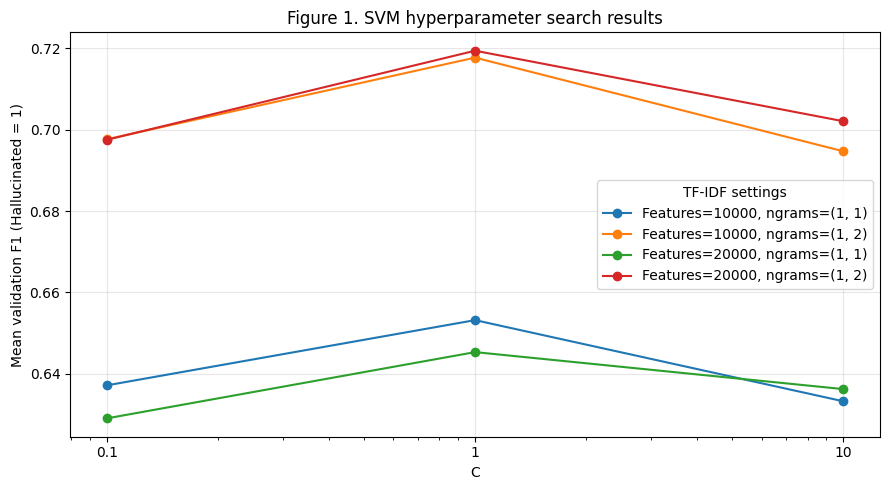

In [12]:
import matplotlib.pyplot as plt

# Plot validation F1 for each TF-IDF configuration.
fig, ax = plt.subplots(figsize=(9, 5))

for (max_features, ngram_range), subset in results_table.groupby(
    ["Max Features", "N-gram Range"]
):
    subset = subset.sort_values("C")

    ax.plot(
        subset["C"],
        subset["Mean F1"],
        marker="o",
        label=f"Features={max_features}, ngrams={ngram_range}"
    )

ax.set_xscale("log")
ax.set_xticks([0.1, 1.0, 10.0], labels=["0.1", "1", "10"])
ax.set_xlabel("C")
ax.set_ylabel("Mean validation F1 (Hallucinated = 1)")
ax.set_title("Figure 1. SVM hyperparameter search results")
ax.legend(title="TF-IDF settings")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
# Extract validation scores for the selected parameter combination.
best_index = grid_search.best_index_

selected_scores = pd.DataFrame({
    metric: [
        grid_search.cv_results_[f"split{fold}_test_{metric}"][best_index]
        for fold in range(len(cv_splits))
    ]
    for metric in scoring
})

# Use population standard deviation consistently for both models.
comparison_rows = []

for model_name, scores in [
    ("Baseline SVM", baseline_scores),
    ("Grid-selected SVM", selected_scores)
]:
    for metric in scoring:
        comparison_rows.append({
            "Model": model_name,
            "Metric": metric,
            "Mean": scores[metric].mean(),
            "Std": scores[metric].std(ddof=0)
        })

comparison_table = pd.DataFrame(comparison_rows)

print("Table 2. Baseline and grid-selected SVM validation performance")
display(comparison_table.round(4))

Table 2. Baseline and grid-selected SVM validation performance


,Model,Metric,Mean,Std
0,Baseline SVM,accuracy,0.7334,0.0052
1,Baseline SVM,precision,0.7595,0.0094
2,Baseline SVM,recall,0.6835,0.0076
3,Baseline SVM,f1,0.7194,0.0047
4,Grid-selected SVM,accuracy,0.7334,0.0052
5,Grid-selected SVM,precision,0.7595,0.0094
6,Grid-selected SVM,recall,0.6835,0.0076
7,Grid-selected SVM,f1,0.7194,0.0047


## Results Interpretation and Limitations

### Baseline and Selected Model
As shown in Table 2, the baseline and grid-selected SVM achieved the same mean cross-validation scores to four decimal places:

- Accuracy: 0.7334
- Precision: 0.7595
- Recall: 0.6835
- F1-score: 0.7194

GridSearchCV selected the baseline configuration: C = 1.0, max_features = 20000, and ngram_range = (1, 2). Therefore, no improvement over the baseline was found within the tested search space.

Precision was higher than recall for the Hallucinated class. This indicates that the model's hallucination predictions were relatively precise, but it still missed a substantial proportion of actual hallucinated answers.

### Effect of Hyperparameters
Table 1 and Figure 1 show that:

- All tested unigram-and-bigram configurations achieved higher mean validation F1 than the unigram-only configurations.
- C = 1.0 achieved the highest mean validation F1 for each tested TF-IDF configuration.
- Increasing C to 10 did not improve F1. Weaker regularization was not beneficial in these experiments.
- With C = 1.0 and unigrams plus bigrams, increasing max_features from 10000 to 20000 increased mean F1 slightly, from 0.7177 to 0.7194. This difference alone does not establish statistical significance.

### Leakage Prevention and Evaluation Limits
TF-IDF was fitted inside the Pipeline separately for each training fold. GroupKFold prevented the same question from appearing in both training and validation within a fold.

The reported scores are validation results, not final test results. The cross-validation scores were also used to select hyperparameters, so the selected score may be optimistic.

Lower validation performance at C = 10 does not by itself prove overfitting. Overfitting occurs when a model learns training-specific patterns that do not generalize well to unseen data.

### Possible Dataset Shortcuts
TF-IDF represents lexical patterns rather than explicitly checking whether an answer is supported by the knowledge. The model may exploit differences in wording or answer length instead of learning factual consistency.

These shortcuts are possible explanations, not findings established by the current experiments. Question grouping reduces question overlap but does not guarantee that all related contexts or topics are separated.



In [14]:
# Save the fitted TF-IDF + LinearSVC pipeline.
best_svm_pipeline = grid_search.best_estimator_
model_filename = "best_svm_pipeline.pkl"

joblib.dump(best_svm_pipeline, model_filename)

# Verify that the saved pipeline can be loaded correctly.
loaded_pipeline = joblib.load(model_filename)

original_predictions = best_svm_pipeline.predict(X_train.iloc[:5])
loaded_predictions = loaded_pipeline.predict(X_train.iloc[:5])

assert np.array_equal(original_predictions, loaded_predictions), (
    "Predictions changed after saving and loading."
)

print("Saved:", model_filename)
print("Save/load verification passed.")

# Download the model to your computer.
files.download(model_filename)

Saved: best_svm_pipeline.pkl
Save/load verification passed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>